# 10 — Bilevel Optimisation: Learning the Cost Weights

Ported from the mfourdvar *Bi-Level Estimation* chapter and the
*argmin differentiation* notes.

## Two levels

A variational analysis $x^*(\theta)$ is itself a function of the
hyper-parameters $\theta$ of its cost — here the weights of the observation
and prior terms. Bilevel optimisation treats the inner minimisation as a
differentiable layer and tunes $\theta$ with an *outer* objective evaluated
on ground truth:

$$
\begin{aligned}
\theta^* &= \underset{\theta}{\arg\min}\; L\big(x^*(\theta)\big),
  \qquad L(x) = \|x - x_{\text{true}}\|^2 \\
x^*(\theta) &= \underset{x}{\arg\min}\; U(x; \theta),
\qquad
U(x; \theta) = \alpha_{obs} \|m \odot (x - y)\|^2 + \alpha_{prior} \|x - \varphi(x)\|^2 .
\end{aligned}
$$

The inner problem is the weak-constraint state estimate of notebook
[08](08_classical_4dvar_vs_4dvarnet_L63.ipynb): $y$ are the masked, noisy
observations and $\varphi$ is a learned prior whose reconstruction error
plays the role of the model-error term. The outer problem asks a different
question of the same cost: *not* "which $x$ minimises $U$?" but "which $U$
has a minimiser closest to the truth?".

### Why the weights matter

For a linear prior $\varphi(x) = Ax$ the inner problem is a quadratic and
its minimiser is explicit,

$$
x^*(\theta) = \big(\alpha_{obs} M + \alpha_{prior} (I - A)^\top (I - A)\big)^{-1} \alpha_{obs} M y ,
\qquad M = \mathrm{diag}(m),
$$

a generalised Tikhonov (Wiener) filter whose regularisation strength is the
ratio $\alpha_{prior} / \alpha_{obs}$. Too small and the analysis
interpolates the noise; too large and it collapses onto the prior's
*fixed-point set* $\ker(I - A)$ — the states the prior reconstructs
exactly, which for a trained autoencoder is its learned manifold — and
ignores the data. In the Bayesian reading of chapter
[1](../01_problem_setting.md) the weights are inverse error variances and
the right ratio is $\sigma_{obs}^2 / \sigma_{prior}^2$; when the prior is a
neural network nobody knows $\sigma_{prior}$, so the ratio is a knob to be
tuned — by hand, by cross-validation, or, as here, by gradient descent on
held-out truth.

### Differentiating through the argmin

The outer gradient is a chain rule through the inner solution,

$$
\frac{dL}{d\theta} = \frac{\partial L}{\partial x}\Big|_{x^*} \cdot \frac{d x^*}{d\theta} ,
$$

and everything hinges on the *hypergradient* $dx^*/d\theta$. Two routes:

- **Unrolling.** Compute $x_K$ by $K$ explicit gradient steps
  $x_{k+1} = x_k - \eta\, \nabla_x U(x_k; \theta)$ and back-propagate
  through the recursion. Differentiating the update gives the linear
  recursion
  $\frac{dx_{k+1}}{d\theta} = \big(I - \eta\, \nabla^2_x U\big)\frac{dx_k}{d\theta} - \eta\, \partial_\theta \nabla_x U$,
  which is what `jax.grad` through a `lax.scan` evaluates. Memory grows
  with $K$, but the gradient is exact for the analysis you actually
  compute, converged or not.
- **Implicit differentiation.** At a true minimiser
  $\nabla_x U(x^*; \theta) = 0$ for every $\theta$, so differentiating that
  identity (the implicit function theorem) gives
  $\frac{dx^*}{d\theta} = -\big[\nabla_x^2 U\big]^{-1} \partial_\theta \nabla_x U$.
  The outer gradient then needs one linear solve with the inner Hessian,
  by conjugate gradients with Hessian-vector products, and no memory of
  the iterates. It is exact only if the inner solver converged.

The mfourdvar notes summarise the trade as *approximate the solution
(unrolling) versus approximate the gradient (implicit)*. Here the inner
loop is short and unrolled, so `jax.grad` unrolls through it; chapter
[12](../12_adjoint_methods.md) covers `optimistix.ImplicitAdjoint` for the
other route and `OneStepAdjoint` for the cheap approximation in between.

In [1]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax

from vardax import (
    BilinAEPrior1D,
    simulate_lorenz63,
    variational_cost,
    variational_cost_grad,
)
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.patches import extract_patches, trajectory_to_xr_dataset
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import apply_standardization, compute_scaler_params

## 1. Lorenz-63 patches

The same preprocessing pipeline as notebook
[08](08_classical_4dvar_vs_4dvarnet_L63.ipynb): simulate, cut into windows,
mask every other step, add noise, standardise, and split into a training
set (used by the outer objective) and a held-out set (used only for the
final comparison).

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key, sigma=10.0, rho=28.0, beta=8.0 / 3.0, dt=0.01, n_steps=5000, n_burn_in=1000
)
ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
# Split the trajectory in time *before* cutting windows, so no window
# straddles the boundary: windows drawn at random from one trajectory and
# split afterwards would leak test timesteps into the training set.
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=64, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=32, n_timesteps=20, seed=43)
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
B, T, N = batch_train.input.shape
print(f"train {batch_train.input.shape}, test {batch_test.input.shape}")

train (64, 20, 3), test (32, 20, 3)


## 2. A fixed prior

The prior $\varphi$ is a bilinear autoencoder pre-trained on clean
trajectories (as in notebook [07](07_prior_pretraining_L63.ipynb)) and then
frozen: the only things learned below are the two cost weights. Freezing
it is what makes this a *hyper*-parameter problem with two unknowns
rather than the full 4DVarNet training of chapter
[9](../09_4dvarnet.md), where $\theta$ would also contain every weight of
$\varphi$ and of the learned solver — the same bilevel structure with a
much larger outer variable.

In [3]:
prior = BilinAEPrior1D(state_dim=N, latent_dim=8, n_time=T, key=jax.random.PRNGKey(10))
pre_opt = optax.adam(1e-2)
pre_state = pre_opt.init(eqx.filter(prior, eqx.is_array))


@eqx.filter_jit
def pretrain_step(prior, opt_state, x):
    loss, grads = eqx.filter_value_and_grad(lambda p: jnp.mean((x - p(x)) ** 2))(prior)
    updates, opt_state = pre_opt.update(grads, opt_state, prior)
    return eqx.apply_updates(prior, updates), opt_state, loss


for _ in range(300):
    prior, pre_state, pre_loss = pretrain_step(prior, pre_state, batch_train.target)
print(f"prior reconstruction MSE after pre-training: {float(pre_loss):.4f}")

prior reconstruction MSE after pre-training: 0.0027


## 3. The inner solver as a differentiable function

The hyper-parameters are stored as logs so the weights stay positive.
`variational_cost` is a *mean* over all elements, so its gradient is tiny
per element; scaling the step by the number of elements gives a
per-element step size $\eta$ that is easy to reason about (it is gradient
descent on the equivalent *sum* cost).

For the quadratic part of the cost the update contracts the error at the
observed points by a factor $1 - 2\eta\alpha_{obs}$ per step, so with
$\eta = 0.2$ and $\alpha_{obs} = 0.5$ twenty steps reduce it by
$0.8^{20} \approx 0.01$: the inner loop is close to, but not at, its
minimiser, which is precisely the regime where unrolling is the honest
choice of hypergradient.

Note the interplay between the weights and the step. Scaling both
$\alpha$'s by a constant $c$ leaves $\arg\min U$ unchanged but multiplies
the gradient — and therefore the effective step size — by $c$. With
$\eta$ fixed, the overall scale of $(\alpha_{obs}, \alpha_{prior})$ acts as
an inner learning rate and their ratio sets the obs/prior trade-off, so
the outer loop is really learning two distinct things: how much to
regularise, and how far to move in $K$ steps.

In [4]:
N_INNER = 20
ETA = 0.2


def weights(hyper):
    return jnp.exp(hyper["log_alpha_obs"]), jnp.exp(hyper["log_alpha_prior"])


def inner_solve(hyper, batch, prior, n_steps=N_INNER, eta=ETA):
    """K steps of gradient descent on U(x; theta), starting from masked obs."""
    alpha_obs, alpha_prior = weights(hyper)
    n_elem = batch.input.size

    def body(x, _):
        g = variational_cost_grad(x, batch, prior, alpha_obs, alpha_prior)
        x = x - eta * n_elem * g
        return x, variational_cost(x, batch, prior, alpha_obs, alpha_prior)

    x0 = batch.input * batch.mask
    x_star, cost_trace = jax.lax.scan(body, x0, None, length=n_steps)
    return x_star, cost_trace


def outer_loss(hyper, batch, prior):
    x_star, _ = inner_solve(hyper, batch, prior)
    return jnp.mean((x_star - batch.target) ** 2)


hyper_fixed = {"log_alpha_obs": jnp.log(0.5), "log_alpha_prior": jnp.log(0.5)}
mse_fixed_train = float(outer_loss(hyper_fixed, batch_train, prior))
print(f"outer loss with fixed weights (0.5, 0.5): {mse_fixed_train:.4f}")

outer loss with fixed weights (0.5, 0.5): 0.0401


## 4. Outer loop — learn $(\alpha_{obs}, \alpha_{prior})$

`jax.grad(outer_loss)` differentiates through the unrolled inner solver.
The outer optimiser is plain Adam on the two log-weights, and the outer
objective is the reconstruction error on the *training* windows: the
held-out windows are touched only in section 5, so the comparison there
is a fair test of generalisation of the learned weights.

In [5]:
outer_opt = optax.adam(learning_rate=0.05)


@jax.jit
def outer_step(hyper, opt_state):
    loss, grads = jax.value_and_grad(outer_loss)(hyper, batch_train, prior)
    updates, opt_state = outer_opt.update(grads, opt_state, hyper)
    return optax.apply_updates(hyper, updates), opt_state, loss


hyper = dict(hyper_fixed)
opt_state = outer_opt.init(hyper)
hist_alpha, hist_outer = [weights(hyper)], []
for _ in range(150):
    hyper, opt_state, loss = outer_step(hyper, opt_state)
    hist_alpha.append(weights(hyper))
    hist_outer.append(float(loss))
hist_alpha = jnp.array(hist_alpha)

a_obs, a_prior = weights(hyper)
print(f"learned weights: alpha_obs={float(a_obs):.3f}, alpha_prior={float(a_prior):.3f}")
print(f"outer loss: {mse_fixed_train:.4f} -> {hist_outer[-1]:.4f}")

learned weights: alpha_obs=1.738, alpha_prior=0.774
outer loss: 0.0401 -> 0.0049


## 5. Fixed vs learned weights on held-out windows

The learned weights are evaluated on windows the outer loop never saw.
Read the three panels together: the weights move away from the arbitrary
$(0.5, 0.5)$ start, the outer objective falls, and the improvement carries
over to held-out data. Look also at *where* the weights went — the ratio
tells you how much the data was trusted relative to the prior, and the
overall scale tells you how aggressive twenty steps needed to be.

held-out MSE: masked obs=0.7609, fixed=0.0627, learned=0.0096


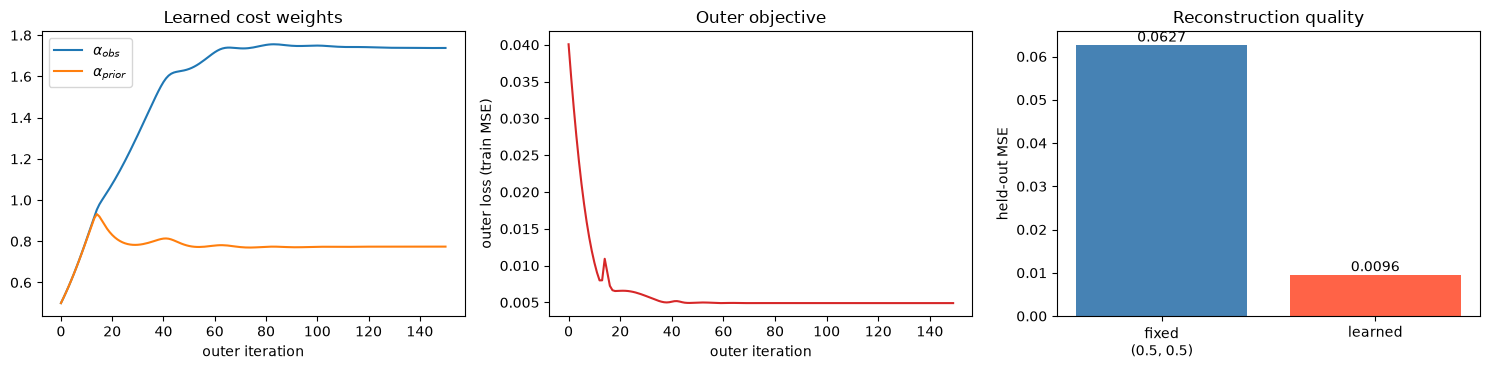

In [6]:
x_fixed, trace_fixed = inner_solve(hyper_fixed, batch_test, prior)
x_learned, trace_learned = inner_solve(hyper, batch_test, prior)
mse_fixed = float(jnp.mean((x_fixed - batch_test.target) ** 2))
mse_learned = float(jnp.mean((x_learned - batch_test.target) ** 2))
mse_obs_only = float(jnp.mean((batch_test.input * batch_test.mask - batch_test.target) ** 2))
print(f"held-out MSE: masked obs={mse_obs_only:.4f}, fixed={mse_fixed:.4f}, learned={mse_learned:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].plot(hist_alpha[:, 0], label=r"$\alpha_{obs}$", color="tab:blue")
axes[0].plot(hist_alpha[:, 1], label=r"$\alpha_{prior}$", color="tab:orange")
axes[0].set_xlabel("outer iteration")
axes[0].set_title("Learned cost weights")
axes[0].legend()

axes[1].plot(hist_outer, color="tab:red")
axes[1].set_xlabel("outer iteration")
axes[1].set_ylabel("outer loss (train MSE)")
axes[1].set_title("Outer objective")

bars = axes[2].bar(
    ["fixed\n(0.5, 0.5)", "learned"],
    [mse_fixed, mse_learned],
    color=["steelblue", "tomato"],
)
for bar, val in zip(bars, [mse_fixed, mse_learned]):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height(),
        f"{val:.4f}",
        ha="center",
        va="bottom",
    )
axes[2].set_ylabel("held-out MSE")
axes[2].set_title("Reconstruction quality")

plt.tight_layout()
plt.show()

The inner cost traces show why: the learned weights change the geometry of
$U$ so that $K$ steps land closer to the truth, even though the cost value
itself is not what the outer loop optimises. A lower inner cost is not the
goal — the truth does not minimise $U$ for any weights, since the prior is
imperfect and the observations are noisy — so the outer loop is free to
pick weights whose minimiser is *wrong in a useful direction*. This is
the general lesson of bilevel DA: the inner cost is an instrument, and
ground truth (or any independent validation signal) is what calibrates it.

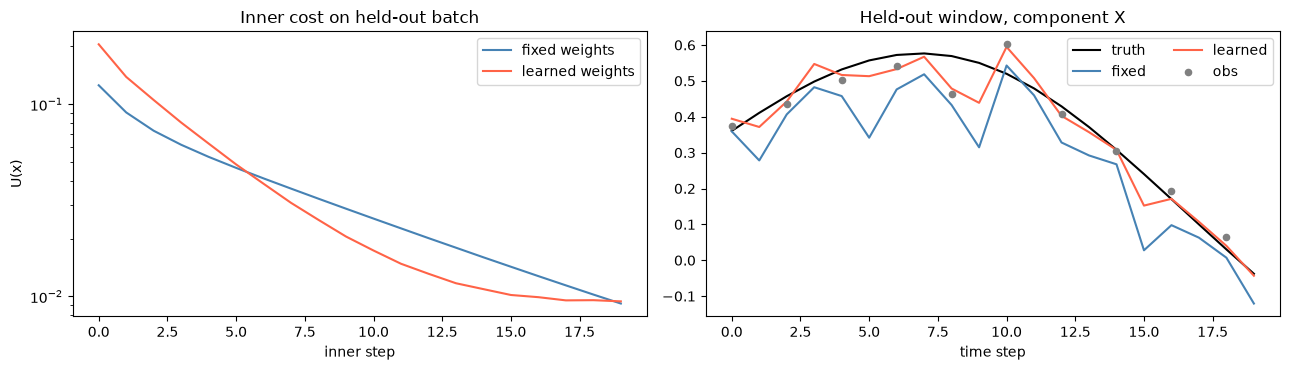

In [7]:
sample, feature = 0, 0
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

axes[0].semilogy(trace_fixed, label="fixed weights", color="steelblue")
axes[0].semilogy(trace_learned, label="learned weights", color="tomato")
axes[0].set_xlabel("inner step")
axes[0].set_ylabel("U(x)")
axes[0].set_title("Inner cost on held-out batch")
axes[0].legend()

axes[1].plot(batch_test.target[sample, :, feature], color="black", label="truth")
axes[1].plot(x_fixed[sample, :, feature], color="steelblue", label="fixed")
axes[1].plot(x_learned[sample, :, feature], color="tomato", label="learned")
axes[1].scatter(
    range(T),
    jnp.where(batch_test.mask[sample, :, feature] > 0, batch_test.input[sample, :, feature], jnp.nan),
    color="gray",
    s=20,
    label="obs",
    zorder=5,
)
axes[1].set_xlabel("time step")
axes[1].set_title("Held-out window, component X")
axes[1].legend(ncol=2)

plt.tight_layout()
plt.show()

## Summary

- Any analysis produced by a differentiable inner solver is a function of
  the cost's hyper-parameters; an outer objective on ground truth turns
  hand-tuning of the regularisation ratio into optimisation.
- The hypergradient $dx^*/d\theta$ can be obtained by unrolling the inner
  iterations (exact for the computed analysis, $O(K)$ memory) or by the
  implicit function theorem at the minimiser (one Hessian solve, $O(1)$
  memory, exact only at convergence). Here the inner loop is unrolled
  gradient descent on `variational_cost`; for large states use
  `optimistix` with `ImplicitAdjoint` (chapter
  [12](../12_adjoint_methods.md)) or the one-step adjoint of notebook
  [02](02_unrolling_vs_fixedpoint_L63.ipynb).
- The same mechanism learns any other cost hyper-parameter — the inner
  step size, the prior's own weights (that is 4DVarNet, chapter
  [9](../09_4dvarnet.md)), the ODE parameters of notebook
  [09](09_param_estimation_L63.ipynb), or the update rule itself (notebook
  [11](11_gradient_learning_L63.ipynb)).